# Modèles Génératifs pour l'Image — Master MVA
## Projet-05: Pseudoinverse-Guided Diffusion Models for Inverse Problems
## Gloire LINVANI et Dorval MOBENDZA
#
 Ce notebook reprend le DDPM U-Net FFHQ 256 déjà chargé dans le TP9 et conduit des expériences pour comparer :
 - **DPS** (Diffusion Posterior Sampling, Chung et al., ICLR 2023),
 - **ΠGDM** (Pseudoinverse-Guided Diffusion Models, Song et al., ICLR 2023).

 Expériences:
 1. **Inpainting** sur masque central carré 128 x 128 et sur des masques aléatoires avec augmentation progressive du nombre de pixels manquants.
 2. **Gaussian deblurring** sans bruit de mesure et avec augmentation progressive du bruit.




# 0. Depedencies, display functions and model loading

In [ ]:
!pip -q install torch torchvision numpy matplotlib pillow tqdm scikit-image lpips

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 2.6 MB/s eta 0:00:00


In [ ]:
# Download files
!git clone https://github.com/DPS2022/diffusion-posterior-sampling.git
!cp -r diffusion-posterior-sampling/guided_diffusion guided_diffusion
!wget -nc -O ffhq256-1k-validation.zip 'https://www.dropbox.com/scl/fi/pppstbdsf0em6o0qscruc/ffhq256-1k-validation.zip?rlkey=xl7nwv2nxb6yvsirr3wad77hm'
!unzip -nq ffhq256-1k-validation.zip
!wget -nc -O ffhq_10m.pt 'https://www.dropbox.com/scl/fi/pq72vxzxcbygieq5z4gvf/ffhq_10m.pt?rlkey=5sxdj6r4o9f7b7bbp5fxg2f5r'

Cloning into 'diffusion-posterior-sampling'...
remote: Enumerating objects: 82, done.
remote: Counting objects: 100% (59/59), done.
remote: Compressing objects: 100% (30/30), done.
remote: Total 82 (delta 29), reused 29 (delta 29), pack-reused 23 (from 1)
Receiving objects: 100% (82/82), 16.19 MiB | 46.30 MiB/s, done.
Resolving deltas: 100% (30/30), done.
--2026-03-28 18:04:30--  https://www.dropbox.com/scl/fi/pppstbdsf0em6o0qscruc/ffhq256-1k-validation.zip?rlkey=xl7nwv2nxb6yvsirr3wad77hm
Resolving www.dropbox.com (www.dropbox.com)... 162.125.5.18, 2620:100:601d:18::a27d:512
Connecting to www.dropbox.com (www.dropbox.com)|162.125.5.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://uc3ea133bb7c1c53a8f85dd5b678.dl.dropboxusercontent.com/cd/0/inline/C9jyEITwtpz1WVCyLz4cjflv9j_uegQ2G9KncdPM57Mh6_hkMhj28AFZuon8B3wZrDs_vRisj4pZTB5sDSem8QXCB72pCCCxLEVXlpxqoBjoq7nogNpQbAEptO_uq6PRw0o/file# [following]
--2026-03-28 18:04:31--  https://uc3ea133bb7c1c53a8f8

In [ ]:
import torch
import torchvision
import os
import sys
import math
import time
import random
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tempfile
import IPython
import torch.nn.functional as F

from PIL import Image
from tqdm import tqdm
from guided_diffusion.unet import create_model
device = "cuda:0" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda:0


In [ ]:
def tensor2im(x):
    x = 0.5+0.5*x # [-1,1]->[0,1]
    return x.detach().cpu().permute(2,3,1,0).squeeze()

def im2tensor(x):
    x = torch.tensor(x,device=device)
    x = 2*x-1 # [0,1]->[-1,1]
    return x.permute(2,0,1).unsqueeze(0)

def rgb2gray(u):
    return 0.2989 * u[:,:,0] + 0.5870 * u[:,:,1] + 0.1140 * u[:,:,2]

def str2(chars):
    return "{:.2f}".format(chars)

def psnr(uref,ut,M=2):
    rmse = np.sqrt(np.mean((np.array(uref.cpu())-np.array(ut.cpu()))**2))
    return 20*np.log10(M/rmse)

def set_all_seeds(seed: int = 0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def summarize_metric(df, group_cols, metric_cols):
    agg = df.groupby(group_cols)[metric_cols].agg(['mean', 'std']).reset_index()
    agg.columns = ['_'.join(c).strip('_') for c in agg.columns.to_flat_index()]
    return agg


def pick_best_config(df, method_name: str, score_col: str = 'PSNR_mean'):
    sub = df[df['method'] == method_name].copy()
    sub = sub.sort_values([score_col, 'SSIM_mean'], ascending=False)
    return sub.iloc[0].to_dict()


def format_mean_std(mean, std, nd=2):
    return f"{mean:.{nd}f} ± {std:.{nd}f}"

def viewimage(im, normalize=True,vmin=-1,vmax=1,z=1,order=0,titre='',displayfilename=False):
    im = im.detach().cpu().permute(2,3,1,0).squeeze()
    imin= np.array(im).astype(np.float32)
    channel_axis = 2 if len(im.shape)>2 else None
    if z!=1:
        from skimage.transform import rescale
        imin = rescale(imin, z, order=order, channel_axis=channel_axis)
    if normalize:
        if vmin is None:
            vmin = imin.min()
        if vmax is None:
            vmax = imin.max()
        if np.abs(vmax-vmin)>1e-10:
            imin = (imin.clip(vmin,vmax)-vmin)/(vmax-vmin)
        else:
            imin = vmin
    else:
        imin=imin.clip(0,255)/255
    imin=(imin*255).astype(np.uint8)
    filename=tempfile.mktemp(titre+'.png')
    if displayfilename:
        print (filename)
    plt.imsave(filename, imin, cmap='gray')
    IPython.display.display(IPython.display.Image(filename))

In [ ]:
# où se trouve le script pigdm_dps_core.py
sys.path.append('.')

In [ ]:
import importlib
import pigdm_dps_core
importlib.reload(pigdm_dps_core)

from pigdm_dps_core import (
    make_center_mask,
    make_random_mask,
    InpaintingOperator,
    GaussianBlurOperator,
    SuperResolutionOperator,
    ComposedOperator,
    BlurInpaintSR4Operator,
    make_measurement,
    compare_dps_and_pigdm,
    run_dps_or_pigdm,
    run_task_on_indices,
    summarize_two_method_df
)

In [ ]:
model_config = {'image_size': 256,
                'num_channels': 128,
                'num_res_blocks': 1,
                'channel_mult': '',
                'learn_sigma': True,
                'class_cond': False,
                'use_checkpoint': False,
                'attention_resolutions': 16,
                'num_heads': 4,
                'num_head_channels': 64,
                'num_heads_upsample': -1,
                'use_scale_shift_norm': True,
                'dropout': 0.0,
                'resblock_updown': True,
                'use_fp16': False,
                'use_new_attention_order': False,
                'model_path': 'ffhq_10m.pt'}
model = create_model(**model_config)
model = model.to(device)
model.eval();

## DDPM parameters

The DDPM parameters defined in this cell will be used to sample the DDPM model.

The Unet ```model(x,t)``` estimates the residual noise $\varepsilon_t(x_t, t)$ from a noisy image $(x_t, t)$.

The function ```get_eps_from_model(x,t)``` computes $\varepsilon_t(x_t, t)$.

Remark that several variables are already precomputed in the class:
* `T` : $T$
* `reversed_time_steps` : backward $t$ range:  $\{T, T-1, \ldots, 1\}$
* `beta` : $(\beta_t)_{1 \leq t \leq T}$
* `alpha` : $(\alpha_t)_{1 \leq t \leq T}$
* `alphabar` : $(\bar{\alpha}_t)_{1 \leq t \leq T}$
* `alphabar_prev` : $(\bar{\alpha}_{t-1})_{1 \leq t \leq T}$

In [ ]:
T = 1000
time_steps = np.arange(T)
reversed_time_steps = time_steps[::-1]

beta_start = 0.0001
beta_end = 0.02
beta = np.linspace(beta_start, beta_end, T, dtype=np.float64)
alpha = 1.0 - beta
alphabar = np.cumprod(alpha)
betabar = 1-alphabar
alphabar_prev = np.append(1.0, alphabar[:-1])    # alpha_{t-1}

def get_eps_from_model(x, t):
    # the model outputs:
    # - an estimation of the noise eps (chanels 0 to 2)
    # - learnt variances for the posterior  (chanels 3 to 5)
    # (see Improved Denoising Diffusion Probabilistic Models
    # by Alex Nichol, Prafulla Dhariwal
    # for the parameterization)
    # We discard the second part of the output for this practice session.

    with torch.no_grad(): # avoid backprop wrt model parameters
        model_output = model(x, torch.tensor(t, device=device).unsqueeze(0))
    model_output = model_output[:,:3,:,:]
    return(model_output)


def get_eps_from_model_withgrad(x, t):
    # same as get_eps_from_model but kipping gradients
    model_output = model(x, torch.tensor(t, device=device).unsqueeze(0))
    model_output = model_output[:,:3,:,:]
    return(model_output)


# 1. Choix des images test et validation pour le tuning des hyperparamètres



n_tune = 3
n_test = 30
Image index: 00579


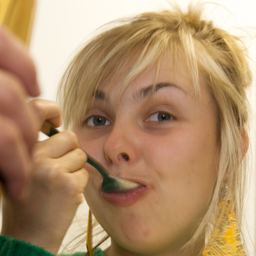

In [ ]:
DATA_DIR = 'ffhq256-1k-validation'

# indices fixes et reproductibles
TUNE_INDICES = [3, 17, 42, 71, 244, 777]

TEST_INDICES = [
    8, 29, 55, 63, 94, 120, 146, 173, 205, 231,
    258, 287, 304, 333, 359, 381, 409, 438, 471, 498,
    526, 551, 579, 603, 641, 688, 715, 742, 801, 923,
]

print('n_tune =', len(TUNE_INDICES))
print('n_test =', len(TEST_INDICES))


def load_image_by_idx(idx: int):
    x = im2tensor(plt.imread(os.path.join(DATA_DIR, f'{idx:05d}.png')))
    return x

idx = random.choice(TEST_INDICES)   # tu peux changer cette image si tu veux
x0 = load_image_by_idx(idx)
imgshape = x0.shape

print(f"Image index: {idx:05d}")
viewimage(x0)

# 2. Visualisation d'un masque d'inpainting

 On crée donc explicitement :
 - le masque,
 - l'opérateur d'inpainting,
 - la mesure `y = H(x)`.

Ground truth


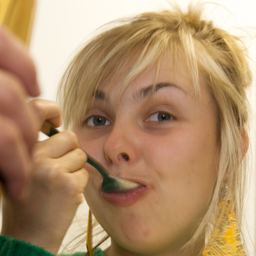

Masked observation


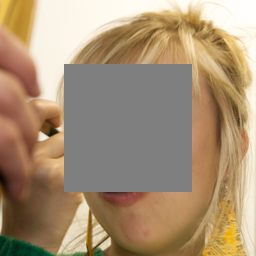

In [ ]:
mask = make_center_mask(imgshape, crop_h=128, crop_w=128, device=device)
inpaint_op = InpaintingOperator(mask)
y_inpaint = make_measurement(x0, inpaint_op, sigma_noise=0.0)

print("Ground truth")
viewimage(x0)
print("Masked observation")
viewimage(inpaint_op.display_measurement(y_inpaint))

## 3. Hyperparamètres candidats

 On optimise les hyperparamètres suivants:

 - DPS :  `zeta_scale`
 - ΠGDM : `num_steps` et `eta`.


In [ ]:
DPS_GRID = [
    {'zeta_scale': z, 'verbose': False}
    for z in [0.03, 0.05, 0.1, 0.2]
]

PIGDM_GRID_INPAINT = [
    {'num_steps': ns, 'eta': eta, 'sigma_noise': 0.0, 'verbose': False}
    for ns, eta in itertools.product([50, 100], [0.0, 0.5, 1.0])
]

PIGDM_GRID_DEBLUR_CLEAN = PIGDM_GRID_INPAINT

# pour le bruité on injectera sigma_noise = sigma_y au moment de l'appel
PIGDM_GRID_DEBLUR_NOISY_BASE = [
    {'num_steps': ns, 'eta': eta, 'verbose': False}
    for ns, eta in itertools.product([50, 100], [0.0, 0.5, 1.0])
]

print('DPS grid:', len(DPS_GRID))
print('PiGDM inpaint grid:', len(PIGDM_GRID_INPAINT))
print('PiGDM deblur clean grid:', len(PIGDM_GRID_DEBLUR_CLEAN))
print('PiGDM deblur noisy base grid:', len(PIGDM_GRID_DEBLUR_NOISY_BASE))

DPS grid: 4
PiGDM inpaint grid: 6
PiGDM deblur clean grid: 6
PiGDM deblur noisy base grid: 6



# 3. Définition des tâches retenues pour le rapport


 - **Inpainting** : masques aléatoires avec 50% et 70% de pixels manquants
 - **Deblurring clean** : sigma_blur = 3.0, sigma_y = 0
 - **Deblurring noisy** : sigma_blur = 3.0, sigma_y in {0.02, 0.05, 0.10}

In [ ]:
INPAINT_RATIOS = [0.5, 0.7]
SIGMA_BLUR = 3.0
SIGMA_NOISY_LIST = [0.02, 0.05, 0.10]
EXAMPLE_IDX = TEST_INDICES[0]  # un seul exemple pour les analyses qualitatives sur les différents problèmes

# 5. Tunning sur le jeu de validation

In [ ]:
def tune_dps(task_name, indices):
    rows = []
    for cfg in DPS_GRID:
        df = run_task_on_indices(
            indices,
            task_name,
            dps_kwargs=cfg,
            pigdm_kwargs={},
            method='DPS'
        )
        rows.append({
            'method': 'DPS',
            'task': task_name,
            'config': str(cfg),
            'cfg': cfg,
            'PSNR_mean': df['DPS_PSNR'].mean(),
            'PSNR_std': df['DPS_PSNR'].std(ddof=1),
            'SSIM_mean': df['DPS_SSIM'].mean(),
            'SSIM_std': df['DPS_SSIM'].std(ddof=1),
        })
    return pd.DataFrame(rows)


def tune_pigdm(task_name, indices, grid):
    rows = []
    for cfg in grid:
        df = run_task_on_indices(
            indices,
            task_name,
            dps_kwargs={},
            pigdm_kwargs=cfg,
            method='PiGDM'
        )
        rows.append({
            'method': 'PiGDM',
            'task': task_name,
            'config': str(cfg),
            'cfg': cfg,
            'PSNR_mean': df['PiGDM_PSNR'].mean(),
            'PSNR_std': df['PiGDM_PSNR'].std(ddof=1),
            'SSIM_mean': df['PiGDM_SSIM'].mean(),
            'SSIM_std': df['PiGDM_SSIM'].std(ddof=1),
        })
    return pd.DataFrame(rows)

In [ ]:
# ---- tuning INPAINT center 128 x 128 square ----
val_dps_inpaint_center_128 = tune_dps('inpaint_center_128', TUNE_INDICES)

In [ ]:
best_dps_inpaint_center_128 = pick_best_config(val_dps_inpaint_center_128, 'DPS')
print('Best DPS inpaint center 128 x 128:', best_dps_inpaint_center_128['cfg'])

In [ ]:
val_pigdm_inpaint_center_128 = tune_pigdm('inpaint_center_128', TUNE_INDICES, PIGDM_GRID_INPAINT)

In [ ]:
best_pigdm_inpaint_center_128 = pick_best_config(val_pigdm_inpaint_center_128, 'PiGDM')
print('Best PiGDM inpaint center 128 x 128:', best_pigdm_inpaint_center_128['cfg'])

In [ ]:
# ---- tuning INPAINT 50% ----
val_dps_inpaint_50 = tune_dps('inpaint_0.5', TUNE_INDICES)

In [ ]:
best_dps_inpaint_50 = pick_best_config(val_dps_inpaint_50, 'DPS')
print('Best DPS inpaint 50%:', best_dps_inpaint_50['cfg'])

In [ ]:
val_pigdm_inpaint_50 = tune_pigdm('inpaint_0.5', TUNE_INDICES, PIGDM_GRID_INPAINT)

In [ ]:
best_pigdm_inpaint_50 = pick_best_config(val_pigdm_inpaint_50, 'PiGDM')
print('Best PiGDM inpaint 50%:', best_pigdm_inpaint_50['cfg'])

In [ ]:
# ---- tuning INPAINT 70% ----
val_dps_inpaint_70 = tune_dps('inpaint_0.7', TUNE_INDICES)

In [ ]:
best_dps_inpaint_70 = pick_best_config(val_dps_inpaint_70, 'DPS')
print('Best DPS inpaint 70%:', best_dps_inpaint_70['cfg'])

In [ ]:
val_pigdm_inpaint_70 = tune_pigdm('inpaint_0.7', TUNE_INDICES, PIGDM_GRID_INPAINT)

In [ ]:
best_pigdm_inpaint_70 = pick_best_config(val_pigdm_inpaint_70, 'PiGDM')
print('Best PiGDM inpaint 70%:', best_pigdm_inpaint_70['cfg'])

Best DPS inpaint 70%: {'zeta_scale': 0.2, 'verbose': False}
Best PiGDM inpaint 70%: {'num_steps': 100, 'eta': 0.0, 'guidance_scale': 0.05, 'sigma_noise': 0.0, 'verbose': False}


In [ ]:
# ---- tuning DEBLUR CLEAN ----
val_dps_deblur_clean = tune_dps('deblur_clean', TUNE_INDICES)

In [ ]:
best_dps_deblur_clean = pick_best_config(val_dps_deblur_clean, 'DPS')
print('Best DPS deblur clean:', best_dps_deblur_clean['cfg'])

In [ ]:
val_pigdm_deblur_clean = tune_pigdm('deblur_clean', TUNE_INDICES, PIGDM_GRID_DEBLUR_CLEAN)

In [ ]:
best_pigdm_deblur_clean = pick_best_config(val_pigdm_deblur_clean, 'PiGDM')
print('Best PiGDM deblur clean:', best_pigdm_deblur_clean['cfg'])

In [ ]:
# ---- tuning DEBLUR CLEAN ----

COMPOSED_TASKS = [
    'compose_blur_inpaint_sr4_0.5',
    'compose_blur_inpaint_sr4_0.7',
]

best_dps_composed = {}
best_pigdm_composed = {}

for task in COMPOSED_TASKS:
    print(f'\n===== TUNING {task} =====')

    #val_dps = tune_dps(task, TUNE_INDICES)
    #best_dps_composed[task] = pick_best_config(val_dps, 'DPS')
    #print('Best DPS:', best_dps_composed[task]['cfg'])

    val_pigdm = tune_pigdm(task, TUNE_INDICES, PIGDM_GRID_INPAINT)
    best_pigdm_composed[task] = pick_best_config(val_pigdm, 'PiGDM')
    print('Best PiGDM:', best_pigdm_composed[task]['cfg'])


===== TUNING compose_blur_inpaint_sr4_0.5 =====
Best PiGDM: {'num_steps': 100, 'eta': 1.0, 'sigma_noise': 0.0, 'verbose': False}

===== TUNING compose_blur_inpaint_sr4_0.7 =====
Best PiGDM: {'num_steps': 100, 'eta': 1.0, 'sigma_noise': 0.0, 'verbose': False}


In [ ]:
best_dps_composed = {}
for task in COMPOSED_TASKS:
    best_dps_composed[task] = {'cfg': {'zeta_scale': 0.2, 'verbose': False}}

In [ ]:
# ---- tuning COMPOSED TASK ----
COMPOSED_TASKS = [
    'compose_blur_inpaint_sr_0.5',
    'compose_blur_inpaint_sr_0.7',
    'compose_inpaint_sr_mask_0.5',
    'compose_inpaint_sr_mask_0.7',
]

best_dps_composed = {}
best_pigdm_composed = {}

for task in COMPOSED_TASKS:
    print(f'\n===== TUNING {task} =====')

    val_dps = tune_dps(task, TUNE_INDICES)
    best_dps_composed[task] = pick_best_config(val_dps, 'DPS')
    print('Best DPS:', best_dps_composed[task]['cfg'])

    val_pigdm = tune_pigdm(task, TUNE_INDICES, PIGDM_GRID_INPAINT)
    best_pigdm_composed[task] = pick_best_config(val_pigdm, 'PiGDM')
    print('Best PiGDM:', best_pigdm_composed[task]['cfg'])


===== TUNING compose_blur_inpaint_sr_0.5 =====
Best PiGDM: {'num_steps': 100, 'eta': 0.0, 'sigma_noise': 0.0, 'verbose': False}

===== TUNING compose_blur_inpaint_sr_0.7 =====
Best PiGDM: {'num_steps': 100, 'eta': 1.0, 'sigma_noise': 0.0, 'verbose': False}

===== TUNING compose_inpaint_sr_mask_0.5 =====
Best PiGDM: {'num_steps': 100, 'eta': 1.0, 'sigma_noise': 0.0, 'verbose': False}

===== TUNING compose_inpaint_sr_mask_0.7 =====
Best PiGDM: {'num_steps': 100, 'eta': 0.0, 'sigma_noise': 0.0, 'verbose': False}


# 6. Évaluation finale sur 30 images (avec les meilleurs réglages)

In [ ]:
# ---- final eval INPAINT 50% ----
test_inpaint_50 = run_task_on_indices(
    TEST_INDICES,
    'inpaint_0.5',
    dps_kwargs=best_dps_inpaint_50['cfg'],
    pigdm_kwargs=best_pigdm_inpaint_50['cfg'],
    show_example=True,
    example_idx=EXAMPLE_IDX,
)

In [ ]:
# ---- final eval INPAINT 70% ----
test_inpaint_70 = run_task_on_indices(
    TEST_INDICES,
    'inpaint_0.7',
    dps_kwargs=best_dps_inpaint_70['cfg'],
    pigdm_kwargs=best_pigdm_inpaint_70['cfg'],
)

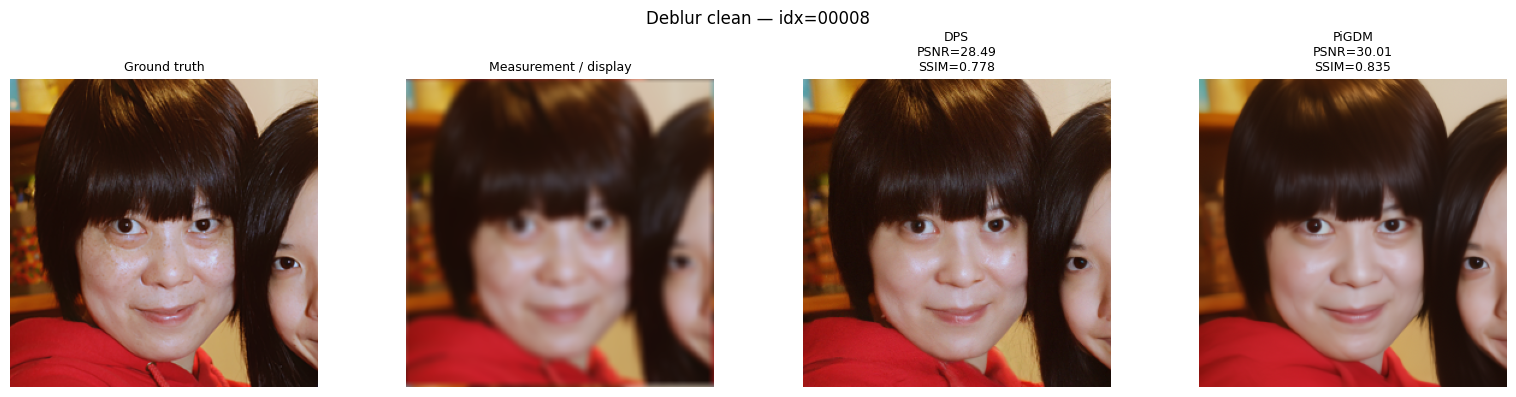

In [ ]:
# ---- final eval DEBLUR CLEAN ----
test_deblur_clean = run_task_on_indices(
    TEST_INDICES,
    'deblur_clean',
    dps_kwargs=best_dps_deblur_clean['cfg'],
    pigdm_kwargs=best_pigdm_deblur_clean['cfg'],
    show_example=True,
    example_idx=EXAMPLE_IDX,
)

In [ ]:
# ---- final eval DEBLUR NOISY ----
test_deblur_noisy = []
for sigma_y in SIGMA_NOISY_LIST:
    df = run_task_on_indices(
        TEST_INDICES,
        f'deblur_noisy_{sigma_y}',
        dps_kwargs=best_dps_deblur_noisy[sigma_y]['cfg'],
        pigdm_kwargs=best_pigdm_deblur_noisy[sigma_y]['cfg'],
        show_example=(sigma_y == 0.05),
        example_idx=EXAMPLE_IDX,
    )
    df['sigma_y'] = sigma_y
    test_deblur_noisy.append(df)

test_deblur_noisy = pd.concat(test_deblur_noisy, ignore_index=True)


--- Displaying example for deblur_noisy_0.02 ---


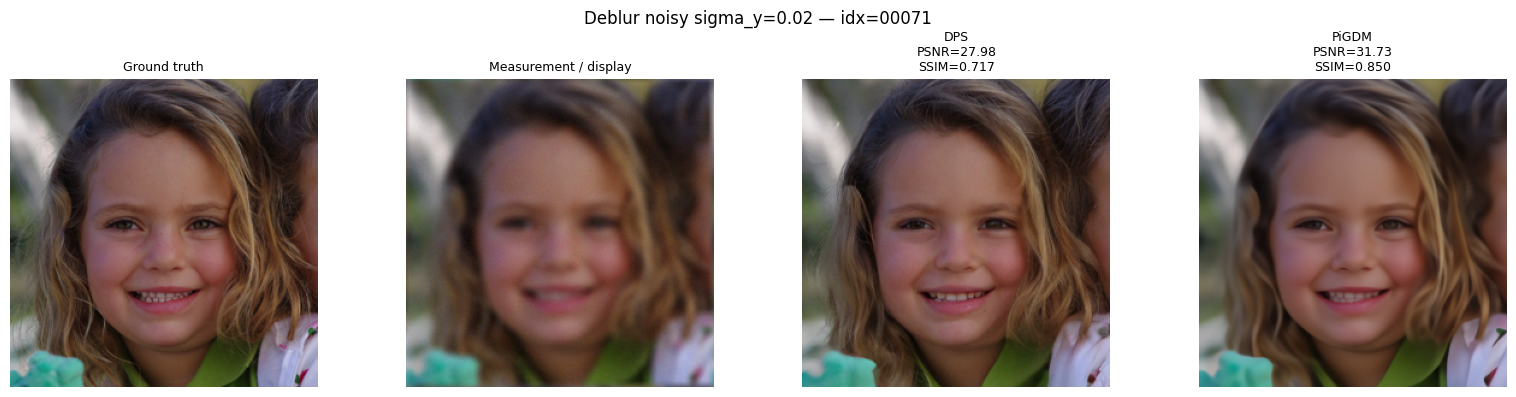


--- Displaying example for deblur_noisy_0.05 ---


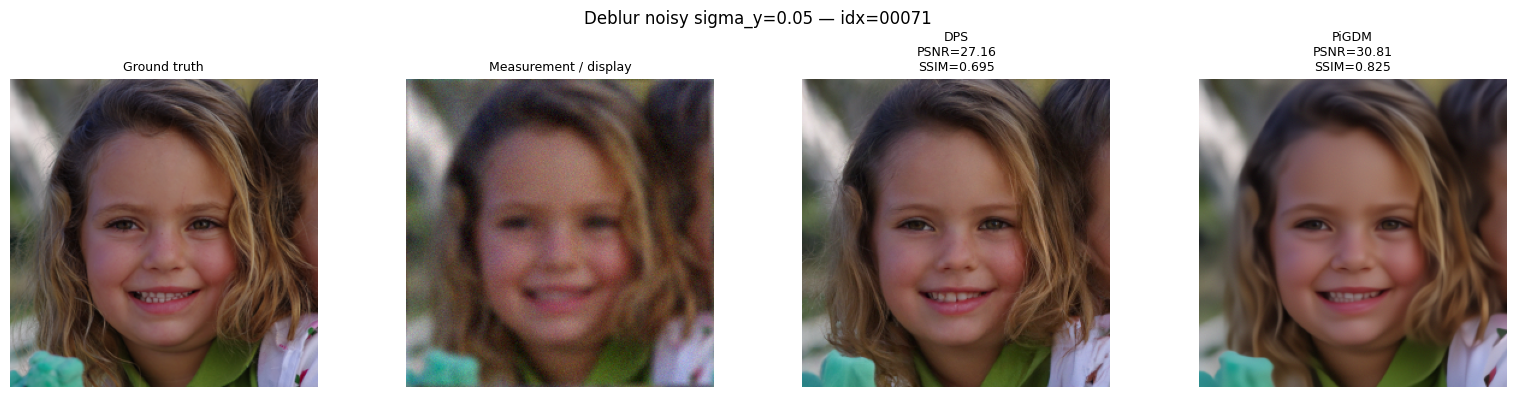


--- Displaying example for deblur_noisy_0.1 ---


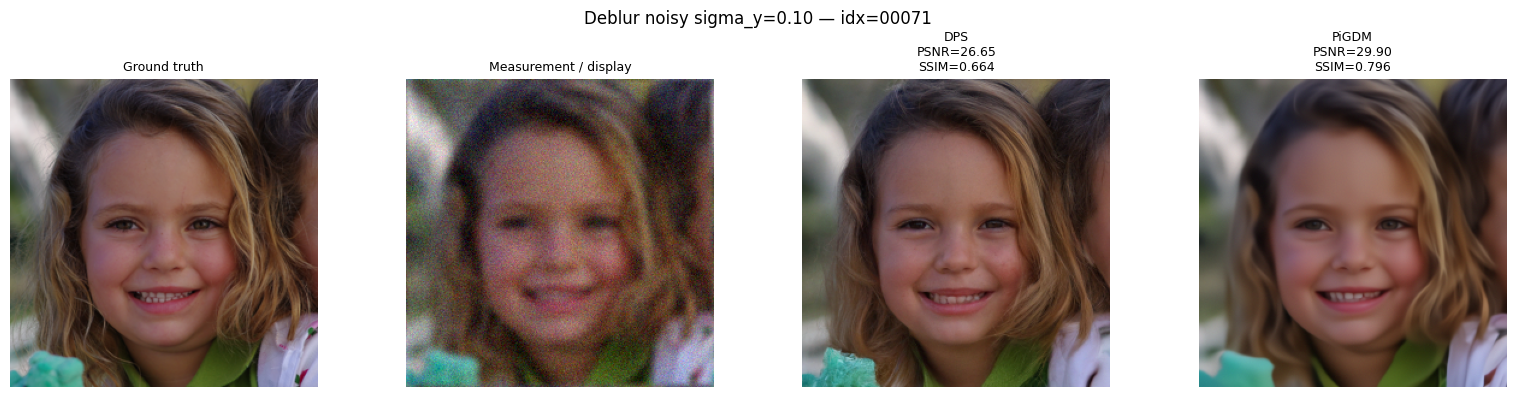

In [ ]:
for sigma_y in SIGMA_NOISY_LIST:
    task_name = f'deblur_noisy_{sigma_y}'
    print(f"\n--- Displaying example for {task_name} ---")
    _ = run_task_on_indices(
        [EXAMPLE_IDX], # Use only the example index for display
        task_name,
        dps_kwargs=best_dps_deblur_noisy[sigma_y]['cfg'],
        pigdm_kwargs=best_pigdm_deblur_noisy[sigma_y]['cfg'],
        show_example=True,
        example_idx=EXAMPLE_IDX,
        batch_size=1, # Ensure batch size is 1 for single image display
    )


===== FINAL EVAL compose_blur_inpaint_sr4_0.5 =====


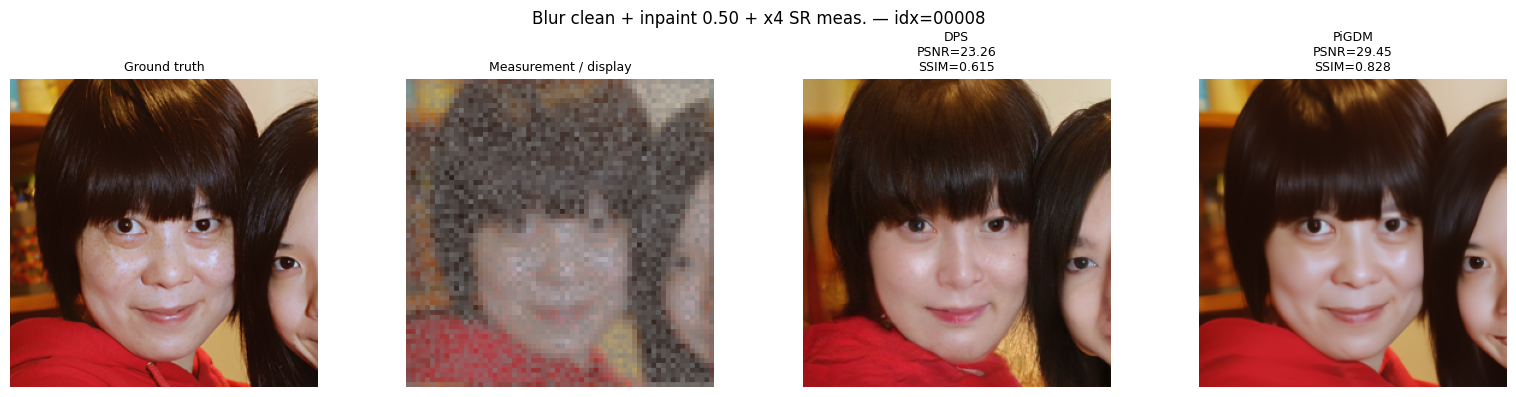

,idx,task,DPS_PSNR,PiGDM_PSNR,DPS_SSIM,PiGDM_SSIM
0,8,compose_blur_inpaint_sr4_0.5,23.256047,29.446771,0.615469,0.827612
1,29,compose_blur_inpaint_sr4_0.5,26.992345,32.186937,0.689607,0.880965
2,55,compose_blur_inpaint_sr4_0.5,23.650753,27.486807,0.728945,0.851407
3,63,compose_blur_inpaint_sr4_0.5,25.037370,29.496543,0.703152,0.852834
4,94,compose_blur_inpaint_sr4_0.5,22.059038,26.127376,0.636710,0.805720
5,120,compose_blur_inpaint_sr4_0.5,22.732141,27.960331,0.711361,0.873891
6,146,compose_blur_inpaint_sr4_0.5,17.307278,21.053629,0.457991,0.713716
7,173,compose_blur_inpaint_sr4_0.5,20.519959,25.509424,0.551372,0.796065
8,205,compose_blur_inpaint_sr4_0.5,27.472254,32.340291,0.728090,0.855001
9,231,compose_blur_inpaint_sr4_0.5,23.890001,28.816551,0.679258,0.859246


,Task,Method,PSNR_mean,PSNR_std,SSIM_mean,SSIM_std
0,compose_blur_inpaint_sr4_0.5,DPS,23.291719,2.982090,0.650196,0.087755
1,compose_blur_inpaint_sr4_0.5,PiGDM,28.042466,3.326272,0.831646,0.049694



===== FINAL EVAL compose_blur_inpaint_sr4_0.7 =====


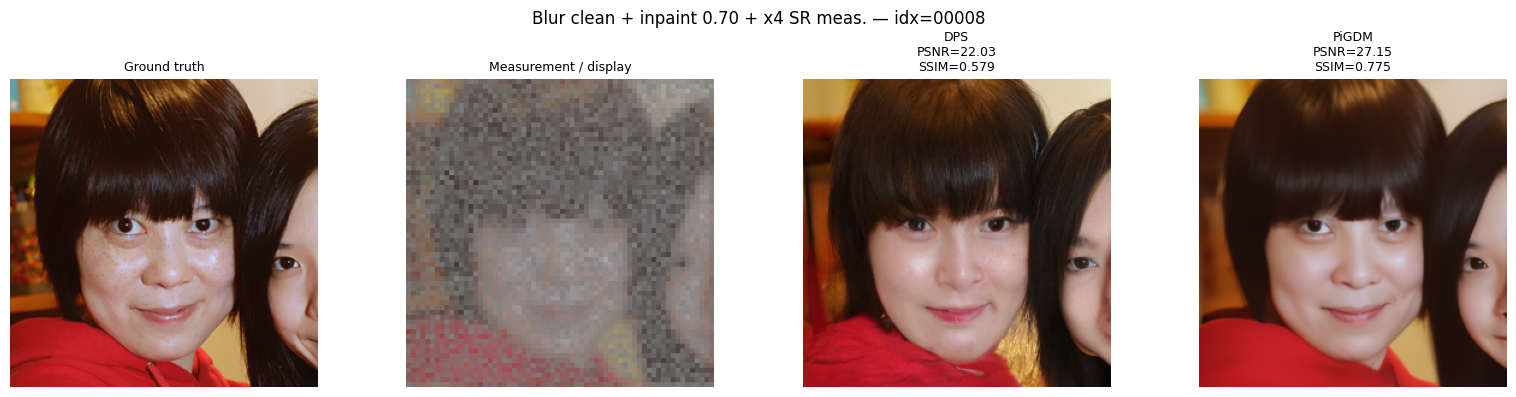

,idx,task,DPS_PSNR,PiGDM_PSNR,DPS_SSIM,PiGDM_SSIM
0,8,compose_blur_inpaint_sr4_0.7,22.034156,27.152515,0.579059,0.775021
1,29,compose_blur_inpaint_sr4_0.7,25.538116,30.391213,0.656104,0.851562
2,55,compose_blur_inpaint_sr4_0.7,22.390569,26.065557,0.704409,0.702986
3,63,compose_blur_inpaint_sr4_0.7,23.315051,28.090235,0.672651,0.801680
4,94,compose_blur_inpaint_sr4_0.7,21.096899,25.872002,0.603473,0.779801
5,120,compose_blur_inpaint_sr4_0.7,21.448409,26.281364,0.681656,0.834818
6,146,compose_blur_inpaint_sr4_0.7,16.490727,19.803822,0.407856,0.622556
7,173,compose_blur_inpaint_sr4_0.7,19.098616,24.037691,0.501697,0.729632
8,205,compose_blur_inpaint_sr4_0.7,26.028086,30.277232,0.689159,0.804510
9,231,compose_blur_inpaint_sr4_0.7,22.034850,27.546559,0.623410,0.795980


,Task,Method,PSNR_mean,PSNR_std,SSIM_mean,SSIM_std
0,compose_blur_inpaint_sr4_0.7,DPS,21.947548,2.798620,0.611947,0.094339
1,compose_blur_inpaint_sr4_0.7,PiGDM,26.551819,3.072545,0.769855,0.068072


In [ ]:
COMPOSED_TEST_INDICES = TEST_INDICES[:10]

test_composed = {}

for task in COMPOSED_TASKS:
    print(f'\n===== FINAL EVAL {task} =====')

    df = run_task_on_indices(
        COMPOSED_TEST_INDICES,
        task,
        dps_kwargs=best_dps_composed[task]['cfg'],
        pigdm_kwargs=best_pigdm_composed[task]['cfg'],
        show_example=True,
        example_idx=COMPOSED_TEST_INDICES[0],
    )

    test_composed[task] = df

    summary = pd.DataFrame([
        {
            'Task': task,
            'Method': 'DPS',
            'PSNR_mean': df['DPS_PSNR'].mean(),
            'PSNR_std': df['DPS_PSNR'].std(ddof=1),
            'SSIM_mean': df['DPS_SSIM'].mean(),
            'SSIM_std': df['DPS_SSIM'].std(ddof=1),
        },
        {
            'Task': task,
            'Method': 'PiGDM',
            'PSNR_mean': df['PiGDM_PSNR'].mean(),
            'PSNR_std': df['PiGDM_PSNR'].std(ddof=1),
            'SSIM_mean': df['PiGDM_SSIM'].mean(),
            'SSIM_std': df['PiGDM_SSIM'].std(ddof=1),
        },
    ])

    display(df)
    display(summary)

# 7. Resultats

In [ ]:
final_table = pd.concat([
    summarize_two_method_df(test_inpaint_50, 'Inpainting 50%'),
    summarize_two_method_df(test_inpaint_70, 'Inpainting 70%'),
    summarize_two_method_df(test_deblur_clean, 'Deblur clean'),
    *[
        summarize_two_method_df(
            test_deblur_noisy[test_deblur_noisy['sigma_y'] == sigma_y],
            f'Deblur noisy σy={sigma_y}'
        )
        for sigma_y in SIGMA_NOISY_LIST
    ]
], ignore_index=True)

final_table

,Task,Method,PSNR,SSIM
0,Inpainting 50%,DPS,31.52 ± 2.35,0.867 ± 0.040
1,Inpainting 50%,PiGDM,26.71 ± 1.88,0.759 ± 0.051
2,Inpainting 70%,DPS,29.93 ± 2.41,0.837 ± 0.048
3,Inpainting 70%,PiGDM,24.20 ± 1.73,0.684 ± 0.058
4,Deblur clean,DPS,28.19 ± 2.41,0.787 ± 0.054
5,Deblur clean,PiGDM,29.95 ± 1.78,0.838 ± 0.035
6,Deblur noisy σy=0.02,DPS,27.79 ± 2.30,0.772 ± 0.053
7,Deblur noisy σy=0.02,PiGDM,12.45 ± 1.91,0.302 ± 0.094
8,Deblur noisy σy=0.05,DPS,27.15 ± 2.17,0.751 ± 0.055
9,Deblur noisy σy=0.05,PiGDM,20.20 ± 2.28,0.562 ± 0.094


# 8. courbes

<>:21: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:21: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2620/896073253.py:21: SyntaxWarning: invalid escape sequence '\s'
  plt.xlabel('Measurement noise $\sigma_y$')
/tmp/ipykernel_2620/896073253.py:31: SyntaxWarning: invalid escape sequence '\s'
  plt.xlabel('Measurement noise $\sigma_y$')


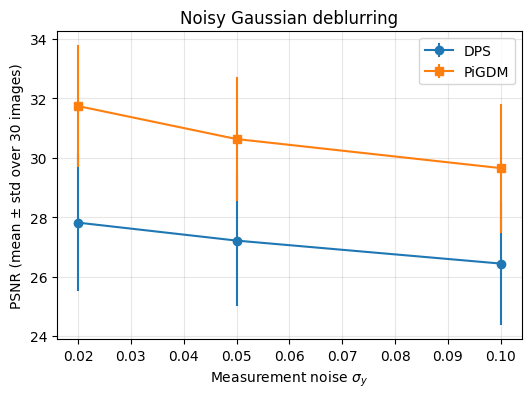

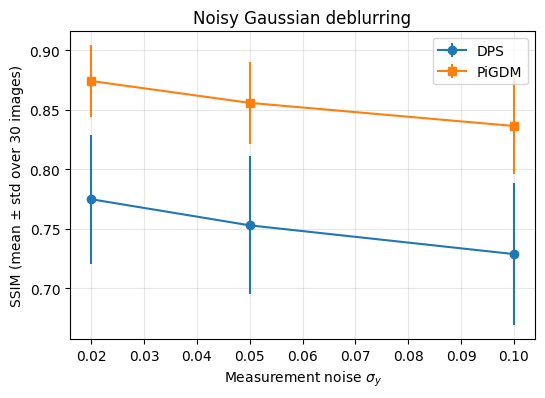

In [ ]:
# Deblur noisy curve
rows_plot = []
for sigma_y in SIGMA_NOISY_LIST:
    df = test_deblur_noisy[test_deblur_noisy['sigma_y'] == sigma_y]
    rows_plot.append({
        'sigma_y': sigma_y,
        'DPS_PSNR_mean': df['DPS_PSNR'].mean(),
        'DPS_PSNR_std': df['DPS_PSNR'].std(ddof=1),
        'PiGDM_PSNR_mean': df['PiGDM_PSNR'].mean(),
        'PiGDM_PSNR_std': df['PiGDM_PSNR'].std(ddof=1),
        'DPS_SSIM_mean': df['DPS_SSIM'].mean(),
        'DPS_SSIM_std': df['DPS_SSIM'].std(ddof=1),
        'PiGDM_SSIM_mean': df['PiGDM_SSIM'].mean(),
        'PiGDM_SSIM_std': df['PiGDM_SSIM'].std(ddof=1),
    })
plot_df = pd.DataFrame(rows_plot)

plt.figure(figsize=(6,4))
plt.errorbar(plot_df['sigma_y'], plot_df['DPS_PSNR_mean'], yerr=plot_df['DPS_PSNR_std'], marker='o', label='DPS')
plt.errorbar(plot_df['sigma_y'], plot_df['PiGDM_PSNR_mean'], yerr=plot_df['PiGDM_PSNR_std'], marker='s', label='PiGDM')
plt.xlabel('Measurement noise $\sigma_y$')
plt.ylabel('PSNR (mean ± std over 30 images)')
plt.title('Noisy Gaussian deblurring')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(6,4))
plt.errorbar(plot_df['sigma_y'], plot_df['DPS_SSIM_mean'], yerr=plot_df['DPS_SSIM_std'], marker='o', label='DPS')
plt.errorbar(plot_df['sigma_y'], plot_df['PiGDM_SSIM_mean'], yerr=plot_df['PiGDM_SSIM_std'], marker='s', label='PiGDM')
plt.xlabel('Measurement noise $\sigma_y$')
plt.ylabel('SSIM (mean ± std over 30 images)')
plt.title('Noisy Gaussian deblurring')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [ ]:
#-----------Sauvegardes-----------#
os.makedirs('results_benchmark', exist_ok=True)
final_table.to_csv('results_benchmark/final_table_mean_std.csv', index=False)
test_inpaint_50.to_csv('results_benchmark/test_inpaint_50_per_image.csv', index=False)
test_inpaint_70.to_csv('results_benchmark/test_inpaint_70_per_image.csv', index=False)
test_deblur_clean.to_csv('results_benchmark/test_deblur_clean_per_image.csv', index=False)
test_deblur_noisy.to_csv('results_benchmark/test_deblur_noisy_per_image.csv', index=False)

print('Saved CSV files in results_benchmark/')

Saved CSV files in results_benchmark/
